# Readout probes: what can be read from the frozen PFN's state at BO contexts?

## Description

<!-- Written 2026-11-11 before the first run (pre-registration). Design: research_log/decisions/0006 §1. Issue #13. -->

**Question.** The round-1 value head (notebook 06) could not rank candidates, although clairvoyant headroom exists. It read the PFN's last-layer *query* states plus hand features. 0006 proposes a decoder that reads the context tokens' residual states at *every* layer. Before building it, small probes check whether the information is there:
- Is it readable from the frozen PFN's state at the BO contexts where the headroom sits?
- Do all layers carry more of it than the last layer, and more than the hand features?

**Setup.**
- *States*: the 4000 labeled states of `api_round1/pilot_20261111-133311` (split 4, d = 2, one per task, branch steps uniform over T = 20, 80% from EI rollouts). Pinned by sha256.
  - Probes are fit on 80% of the states and evaluated on the held-out 20%. Every state is a different task, so the split is by task.
- *Inputs*:
  - **hand**: the round-1 head's global features, plus its per-candidate features for candidate targets;
  - **last**: the last layer's context states, pooled (mean, max, and the incumbent's token), plus the candidate's last-layer query state;
  - **all**: the same at the embedding and after each of the 8 blocks.
- *Probes*: ridge regression (regularization chosen on held-out training tasks) and a one-hidden-layer MLP (256 units, early stopping). Small on purpose: they test readability, not modelling.
- *State targets* (ground truth from the task redrawn from its seed):
  - the remaining gap of the incumbent to f\* (% of the task's gap);
  - x\* (location);
  - the number of relevant inputs (from the prior);
  - roughness (log mean gradient norm);
  - the clairvoyant headroom of the state (cross-fitted best label advantage), and whether it exceeds 0.5 % of the gap (about the top 10%: "deviating pays here").
- *Candidate targets* (the 15 labeled non-base candidates per state):
  - the ground-truth advantage label;
  - one-step KG by re-encoding the PFN (8 stratified fantasies; a model quantity that tests whether lookahead information is linearly or shallowly readable).
- *Ceiling*: the split-half reliability of the advantage labels: the within-state Spearman between the labels from continuation replicates {0, 1} and {2, 3}. No probe can rank candidates better than the labels agree with themselves.
- *Metrics*: R² and Spearman for regression (the contrasts use Spearman, and R² for x\*); AUC for headroom_bin; mean within-state Spearman for candidate targets. Each comes with a bootstrap 95% CI over test states, and the contrasts all − last, all − hand and last − hand are paired bootstraps.

**Revision after the sanity run (2026-11-11 16:25, before the pilot).** The gap and the headroom are heavy-tailed: the gap has a median of 0.17 % and a maximum of 182 %, and the headroom reaches 18. On 60 states, R² on the raw scale was dominated by single states. So the probes now fit log10(gap + 1e-3) and asinh(headroom), and the advantage label is fit as asinh(adv); these are monotone, so ranks are unchanged. Spearman is added as a rank metric for every scalar state target. The decision targets and the rule are unchanged.

**What to look for.**
- The decision-relevant targets: headroom_bin and adv.
- The joint targets: gap_inc and x\*, as 0006 §1 sets out. If last-layer probes fail and all-layer probes succeed, the all-layer readout is confirmed. If both fail on joint targets, that argues for α-PFN information features or a joint head.
- KG readability.

**GO / NO-GO** (rule `analysis/api.py::probe_verdict`):
- **GO** (build the 0006 decoder on all layers): headroom_bin (AUC) or adv (within-state Spearman) is readable from all layers (CI lower bound above chance) *and* all layers beat the hand features (paired CI > 0).
- **NO-GO**: neither is readable from any PFN input. The decoder would then have nothing to read; the next levers are the belief itself (the model-based gate, notebook 07) or PFN fine-tuning (0004/0005).
- **INCONCLUSIVE**: otherwise.

**Limits.**
- One PFN (`pfn_large`, noise-free P0), d = 2, contexts n ≤ 24.
- 4000 states.
- The label-based targets are noisy (4 continuations); the reliability ceiling says how noisy.
- Probes are deliberately small. "Not readable by a small probe" is weaker than "not in the state".


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.api import CHANCE, probe_verdict

SNAPSHOT = "results/api_probe/pilot_20261111-163954"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached pilot experiment=api_probe task.d=2
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261111-163954` |
| commit | `5ce73d21063f` (tag `sweep/api_probe/pilot_20261111-163954`) |
| backend / host | detached / ulysses |
| ran | 2026-11-11T16:39:56 → 2026-11-11T16:53:37 |
| members | 1: 1 done |
| compute | 13.7 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/api_probe.yaml`):

```yaml
# @package _global_
# Readout probes (research_log/decisions/0006 §1): last layer vs all layers of the frozen PFN, against the
# round-1 head's hand features. Pre-registration: notebooks/08_2026-11-11_api_probe.ipynb.
# States: the 4000 labeled states of api_round1's pilot (split 4).
defaults:
  - override /task: api_probe

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  api_candidates.local_sigmas: '[0.01, 0.03, 0.1]'
  api_candidates.n_global: 64
  api_candidates.n_local_per_point: 16
  api_candidates.n_top: 4
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  device: cuda
  draw_chunk: 500
  group: 128
  headroom_threshold: 0.5
  kg_n_y: 8
  labels.path: api_round1/pilot_20261111-133311/0/tracking/artifacts/labels.pt
  labels.sha256: c27d893923d0f003ed7b1e1148ad6670c1f5fb061ac7cdf137eb2a8a64c678d9
  n_boot: 500
  n_init_per_d: 2
  n_states: 4000
  name: api_probe
  pfn: pfn_large
  task_draw.n_dense: 4096
  task_draw.n_refine: 8
  task_draw.refine_steps: 50
  test_frac: 0.2
  tf32: false
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
S = runs.iloc[0]
print("minutes:", {k: round(float(S[k]) / 60, 1) for k in runs.columns if k.startswith("time/")})
probes, contrasts = snap.table("probes"), snap.table("contrasts")
rel, targets = snap.table("reliability"), snap.table("targets")
print("states:", int(S["n_states"]), "| test states:", int(S["n_test"]))
display(rel)
display(targets.drop(columns=["seed"]).groupby("split").describe().T.round(3))

member status: {'DONE': 1}
minutes: {'time/collect_s': 5.1, 'time/targets_s': 5.4}
states: 4000 | test states: 826


,metric,value,n_states,member
0,within_spearman_split_half,0.567569,2992,0


split                  test     train
log_gap      count  826.000  3174.000
             mean    -0.858    -0.859
             std      1.636     1.649
             min     -3.000    -3.000
             25%     -2.690    -2.706
             50%     -0.762    -0.787
             75%      0.602     0.658
             max      2.261     2.043
n_relevant   count  826.000  3174.000
             mean     1.485     1.501
             std      0.500     0.500
             min      1.000     1.000
             25%      1.000     1.000
             50%      1.000     2.000
             75%      2.000     2.000
             max      2.000     2.000
rough        count  826.000  3174.000
             mean    -0.154    -0.155
             std      1.024     1.020
             min     -4.307    -4.816
             25%     -0.824    -0.806
             50%     -0.141    -0.091
             75%      0.504     0.547
             max      2.763     2.593
headroom     count  826.000  3174.000
             mean     0.165     0.203
             std      0.642     0.731
             min     -2.230    -3.259
             25%      0.000     0.000
             50%      0.000     0.000
             75%      0.024     0.033
             max      4.450     5.193
headroom_bin count  826.000  3174.000
             mean     0.096     0.105
             std      0.294     0.306
             min      0.000     0.000
             25%      0.000     0.000
             50%      0.000     0.000
             75%      0.000     0.000
             max      1.000     1.000
t            count  826.000  3174.000
             mean     9.243     9.403
             std      5.982     5.774
             min      0.000     0.000
             25%      4.000     4.000
             50%      9.000     9.000
             75%     15.000    14.000
             max     19.000    19.000
member       count  826.000  3174.000
             mean     0.000     0.000
             std      0.000     0.000
             min      0.000     0.000
             25%      0.000     0.000
             50%      0.000     0.000
             75%      0.000     0.000
             max      0.000     0.000

## 1. What is readable, from which input?

Main metric per target: AUC for headroom_bin, Spearman for scalar state targets, R² for x\* (d values), and the mean within-state Spearman for candidate targets.
The table shows the value and its 95% bootstrap CI over test states; chance is 0.5 for AUC and 0 otherwise.

input                           hand                          \
model                          ridge                     mlp   
target                                                         
headroom_bin    0.681 [0.621, 0.735]    0.665 [0.595, 0.722]   
headroom       0.043 [-0.036, 0.116]   0.062 [-0.009, 0.133]   
adv           -0.018 [-0.044, 0.007]  -0.005 [-0.031, 0.018]   
kg              0.313 [0.283, 0.342]    0.327 [0.294, 0.358]   
log_gap         0.707 [0.667, 0.741]    0.734 [0.695, 0.770]   
xstar          0.000 [-0.006, 0.005]  -0.000 [-0.010, 0.008]   
rough           0.870 [0.849, 0.888]    0.892 [0.873, 0.908]   
n_relevant      0.538 [0.487, 0.593]    0.620 [0.578, 0.660]   

input                           last                         \
model                          ridge                    mlp   
target                                                        
headroom_bin    0.663 [0.599, 0.724]   0.637 [0.575, 0.696]   
headroom        0.109 [0.042, 0.180]  0.069 [-0.003, 0.134]   
adv           -0.003 [-0.029, 0.022]  0.008 [-0.016, 0.032]   
kg              0.212 [0.179, 0.243]   0.272 [0.239, 0.303]   
log_gap         0.763 [0.724, 0.795]   0.773 [0.735, 0.805]   
xstar           0.445 [0.402, 0.486]   0.449 [0.401, 0.496]   
rough           0.910 [0.893, 0.925]   0.916 [0.900, 0.931]   
n_relevant      0.801 [0.780, 0.819]   0.804 [0.784, 0.822]   

input                           all                         
model                         ridge                    mlp  
target                                                      
headroom_bin   0.616 [0.557, 0.683]   0.572 [0.504, 0.633]  
headroom       0.078 [0.007, 0.139]  0.012 [-0.054, 0.077]  
adv           0.008 [-0.018, 0.032]  0.025 [-0.000, 0.052]  
kg             0.258 [0.226, 0.289]   0.288 [0.256, 0.318]  
log_gap        0.775 [0.736, 0.806]   0.746 [0.706, 0.779]  
xstar          0.527 [0.486, 0.567]   0.470 [0.426, 0.512]  
rough          0.929 [0.914, 0.943]   0.906 [0.889, 0.923]  
n_relevant     0.814 [0.796, 0.828]   0.783 [0.755, 0.805]

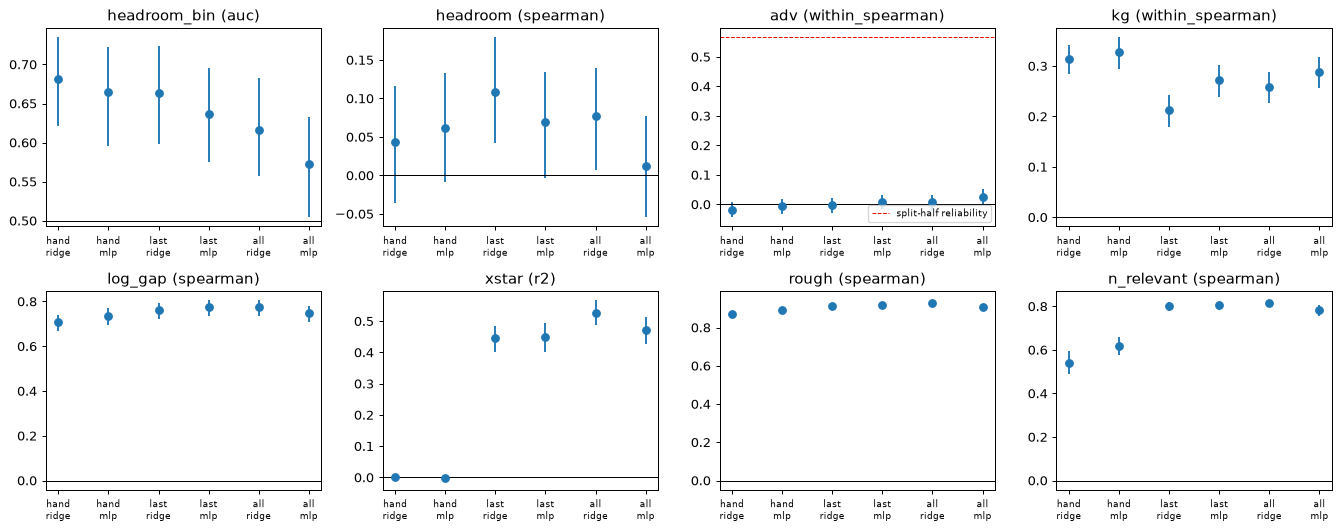

In [ ]:
MAIN = {"headroom_bin": "auc", "xstar": "r2", "adv": "within_spearman", "kg": "within_spearman"}
main = probes.loc[probes.apply(lambda r: r.metric == MAIN.get(r.target, "spearman"), axis=1)].copy()
main["cell"] = main.apply(lambda r: f"{r.value:.3f} [{r.lo:.3f}, {r.hi:.3f}]", axis=1)
order = ["headroom_bin", "headroom", "adv", "kg", "log_gap", "xstar", "rough", "n_relevant"]
tab = main.pivot_table(index="target", columns=["input", "model"], values="cell", aggfunc="first").reindex(order)
display(tab[[("hand", "ridge"), ("hand", "mlp"), ("last", "ridge"), ("last", "mlp"), ("all", "ridge"), ("all", "mlp")]])
fig, axes = plt.subplots(2, 4, figsize=(15, 6), dpi=90)
for ax, tg in zip(axes.ravel(), order):
    m = main.loc[main.target == tg]
    xs = np.arange(len(m))
    ax.errorbar(xs, m.value, yerr=[m.value - m.lo, m.hi - m.value], fmt="o")
    ax.set_xticks(xs, [f"{i}\n{mo}" for i, mo in zip(m.input, m.model)], fontsize=7)
    ax.axhline(CHANCE[MAIN.get(tg, "spearman")] if MAIN.get(tg, "spearman") in CHANCE else 0, color="k", lw=0.8)
    if tg == "adv":
        ax.axhline(float(rel.value.iloc[0]), color="r", ls="--", lw=0.8, label="split-half reliability")
        ax.legend(fontsize=7)
    ax.set_title(f"{tg} ({MAIN.get(tg, 'spearman')})")
plt.tight_layout(); plt.show()

## 2. Contrasts: all layers vs last layer vs hand features (paired over test states)

In [ ]:
c = contrasts.copy()
c["cell"] = c.apply(lambda r: f"{r['diff']:+.3f} [{r.lo:+.3f}, {r.hi:+.3f}]", axis=1)
display(c.pivot_table(index=["target", "metric"], columns=["a", "b", "model"], values="cell", aggfunc="first").reindex(order, level=0))

a                                                 all  \
b                                                hand   
model                                             mlp   
target       metric                                     
headroom_bin auc              -0.093 [-0.162, -0.013]   
headroom     spearman         -0.050 [-0.140, +0.042]   
adv          within_spearman  +0.031 [+0.000, +0.063]   
kg           within_spearman  -0.039 [-0.075, -0.007]   
log_gap      spearman         +0.013 [-0.013, +0.042]   
xstar        r2               +0.470 [+0.428, +0.512]   
rough        spearman         +0.014 [+0.001, +0.026]   
n_relevant   spearman         +0.163 [+0.121, +0.201]   

a                                                      \
b                                                       
model                                           ridge   
target       metric                                     
headroom_bin auc              -0.065 [-0.116, -0.011]   
headroom     spearman         +0.035 [-0.042, +0.115]   
adv          within_spearman  +0.026 [-0.005, +0.056]   
kg           within_spearman  -0.055 [-0.080, -0.026]   
log_gap      spearman         +0.069 [+0.045, +0.094]   
xstar        r2               +0.526 [+0.489, +0.568]   
rough        spearman         +0.059 [+0.045, +0.072]   
n_relevant   spearman         +0.275 [+0.233, +0.322]   

a                                                      \
b                                                last   
model                                             mlp   
target       metric                                     
headroom_bin auc              -0.065 [-0.121, -0.006]   
headroom     spearman         -0.057 [-0.141, +0.025]   
adv          within_spearman  +0.017 [-0.009, +0.046]   
kg           within_spearman  +0.016 [-0.011, +0.046]   
log_gap      spearman         -0.027 [-0.047, -0.008]   
xstar        r2               +0.021 [-0.003, +0.046]   
rough        spearman         -0.010 [-0.020, -0.001]   
n_relevant   spearman         -0.021 [-0.038, -0.005]   

a                                                      \
b                                                       
model                                           ridge   
target       metric                                     
headroom_bin auc              -0.047 [-0.086, -0.008]   
headroom     spearman         -0.031 [-0.081, +0.017]   
adv          within_spearman  +0.012 [-0.009, +0.036]   
kg           within_spearman  +0.045 [+0.023, +0.066]   
log_gap      spearman         +0.012 [+0.004, +0.022]   
xstar        r2               +0.082 [+0.064, +0.097]   
rough        spearman         +0.019 [+0.011, +0.027]   
n_relevant   spearman         +0.013 [+0.005, +0.022]   

a                                                last                           
b                                                hand                           
model                                             mlp                    ridge  
target       metric                                                             
headroom_bin auc              -0.027 [-0.090, +0.037]  -0.018 [-0.059, +0.021]  
headroom     spearman         +0.007 [-0.074, +0.089]  +0.066 [+0.005, +0.135]  
adv          within_spearman  +0.013 [-0.015, +0.043]  +0.014 [-0.017, +0.043]  
kg           within_spearman  -0.055 [-0.091, -0.028]  -0.101 [-0.126, -0.071]  
log_gap      spearman         +0.039 [+0.016, +0.065]  +0.056 [+0.032, +0.083]  
xstar        r2               +0.449 [+0.406, +0.490]  +0.445 [+0.405, +0.483]  
rough        spearman         +0.024 [+0.011, +0.036]  +0.040 [+0.027, +0.053]  
n_relevant   spearman         +0.184 [+0.146, +0.222]  +0.263 [+0.221, +0.309]

## 3. R² of the state targets (scale-dependent; secondary)

In [ ]:
r2 = probes.loc[(probes.level == "state") & (probes.metric == "r2")]
display(r2.pivot_table(index="target", columns=["input", "model"], values="value").round(3))

input         all          hand          last       
model         mlp  ridge    mlp  ridge    mlp  ridge
target                                              
headroom   -0.167 -0.030  0.006  0.001 -0.092  0.010
log_gap     0.532  0.602  0.537  0.488  0.601  0.585
n_relevant  0.638  0.703  0.379  0.255  0.677  0.668
rough       0.834  0.865  0.805  0.733  0.843  0.834
xstar       0.470  0.527 -0.000  0.000  0.449  0.445

## Observations

Snapshot `results/api_probe/pilot_20261111-163954`: 4000 states, 826 test states, 1/1 member DONE. Every number below is from the cell outputs above.

1. **The PFN's state carries the landscape and the joint quantities, and earlier layers add to the last one.**
   - x\*: R² 0.527 [0.486, 0.567] from all layers (ridge); 0.445 from the last; 0.000 from the hand features.
   - Number of relevant inputs: Spearman 0.814 (all), 0.801 (last), 0.538 (hand).
   - Roughness: 0.929 (all) vs 0.910 (last).
   - All − last is positive for x\*, roughness, n_relevant and log_gap with ridge (paired CIs > 0). 0006 §1's premise for the all-layer readout holds for these targets.
2. **The decision-relevant quantities are not readable by small probes from any input.**
   - adv, the within-state Spearman with the label: hand −0.018, last −0.003 to 0.008, all 0.008 to 0.025 (MLP CI [−0.000, 0.052]).
   - The labels' split-half reliability is 0.568. So the labels themselves rank candidates consistently; the probes do not find that ranking in the state.
   - headroom_bin, AUC: hand 0.681 [0.621, 0.735] is the best. All layers are *worse* than hand (ridge −0.065 [−0.116, −0.011]; MLP −0.093). With 3200 training states, the 6912 all-layer state features add variance and no signal.
3. **KG is readable, best from the hand features** (0.313–0.327 within-state Spearman; last layer 0.212–0.272; all layers 0.258–0.288). But adv is not. Either one-step lookahead information is not what separates good from bad candidates at these states, or the clairvoyant label is dominated by events that depend on the true task.
4. **Interpretation for 0006.** The all-layer readout is justified for state description: where the optimum is, and what the landscape is like. It does not by itself make the advantage readable. A decoder that has to learn the advantage from these inputs has to compose the readable parts (x\*, KG, gap) into the advantage, and small probes show no linear or shallow path to it.
   - The decoder pilot (notebook 09) tests whether a deeper, purpose-trained model does better.
   - Limits: probes are small and fit on 3200 states; the candidate probes see 15 candidates per state; d = 2.

**Verdict: INCONCLUSIVE** under the pre-registered rule. Neither decision target is readable from all layers better than from the hand features, but headroom_bin is above chance from PFN inputs (all layers, ridge: 0.616 [0.557, 0.683]), so the rule does not give NO-GO.


## Verdict

In [ ]:
verdict = probe_verdict(probes, contrasts)
print("verdict (analysis/api.py::probe_verdict):", verdict)

verdict (analysis/api.py::probe_verdict): INCONCLUSIVE


## Addendum (2026-11-11 21:10, written before its run): direct scores against the label

This is post hoc and exploratory; the verdict above stands.
- The gate pilot (notebook 07) found a within-state Spearman of 0.042 between the PFN's belief-continuation advantage and the ground-truth label.
- The probes found ≤ 0.025 for every trained readout. KG is readable from the state (0.31–0.33), but whether KG itself ranks the candidates was not checked.

The new table `direct` gives the within-state Spearman, against the advantage label at all labeled states, of untrained scores with no fitting involved:
- KG by re-encoding;
- the PFN's predictive features rel_mu, sd, q05, q95, log EI and PI.

The code change adds only this table (the `direct` block in `tasks/api_probe.py`). It reruns the pilot configuration as a new sweep; the other tables should reproduce.

**Reading.**
- A score clearly above 0.04 would be a cheap ranking signal that the decoder (0006) and the gate missed.
- All scores ≈ 0 would confirm that, at these states, the candidates' ground-truth advantage is not predictable from the belief. Given the label reliability of 0.57, that would make it luck or PFN error.
